# O3 counterfactual branching

**Complete** · All paired outcomes saved · ETA 0h 00m 00s  
Updated 2026-11-12T14:56:20.482074+01:00 · PID 14380

Each origin restores the same MAE, AdamW and pre-action 88-input Lasso. Skip, ¼× and 1× share the initial frame and masks. Every branch then updates at fixed ¼× on the same subsequent frames with masks keyed to seed and stream position. The same origins are used across seeds.

Lower O3 is better. It combines current-image reconstruction MSE and −0.25 × RankMe, with each metric divided by its original seed-specific calibration standard deviation. Immediate scoring uses the arrival and its pre-admission health bank, exactly as O3 did. After 96 and 1,000 updates, reconstruction is averaged over the next 32 arrivals before training on them. RankMe uses the 128-frame slow bank at the measurement cursor. Delayed results assess how well the original one-step ranking transfers to each horizon.

| Seed | Paired origins complete | Source arrivals replayed |
| --- | --- | --- |
 | 2026 | 24/24 | 77,552 | 
 | 2027 | 24/24 | 77,552 | 
 | 2028 | 24/24 | 77,552 | 

## Ranking and regret

| Seed | Origins | Horizon | Top-1 | Pairwise | Mean regret | 90th percentile regret | Winner changed | Immediate winner regret |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | Pooled | 72 | 0 | 52.8% | 61.1% | 0.016316 | 0.040555 | 0.0% | 0.000000 | 
 | Pooled | 72 | 96 | 34.7% | 51.9% | 0.012584 | 0.018011 | 70.8% | 0.014329 | 
 | Pooled | 72 | 1000 | 37.5% | 53.2% | 0.098289 | 0.206034 | 62.5% | 0.081105 | 
 | 2026 | 24 | 0 | 79.2% | 70.8% | 0.006694 | 0.009889 | 0.0% | 0.000000 | 
 | 2026 | 24 | 96 | 37.5% | 45.8% | 0.003042 | 0.006591 | 75.0% | 0.005859 | 
 | 2026 | 24 | 1000 | 50.0% | 58.3% | 0.034319 | 0.141128 | 58.3% | 0.048524 | 
 | 2027 | 24 | 0 | 25.0% | 47.2% | 0.024338 | 0.070819 | 0.0% | 0.000000 | 
 | 2027 | 24 | 96 | 29.2% | 50.0% | 0.022955 | 0.084847 | 70.8% | 0.016881 | 
 | 2027 | 24 | 1000 | 20.8% | 45.8% | 0.212797 | 0.706776 | 58.3% | 0.145356 | 
 | 2028 | 24 | 0 | 54.2% | 65.3% | 0.017915 | 0.031933 | 0.0% | 0.000000 | 
 | 2028 | 24 | 96 | 37.5% | 59.7% | 0.011755 | 0.015745 | 66.7% | 0.020248 | 
 | 2028 | 24 | 1000 | 41.7% | 55.6% | 0.047752 | 0.120704 | 70.8% | 0.049434 | 

Regret is the chosen branch’s measured O3 minus the best measured O3 at that origin. Differences up to 1e-06 O3 units count as ties. Pairwise agreement excludes measured ties and gives half credit to predicted ties. Winner changed means no immediate winner is still optimal.

## Seed 2027 paired comparison

| Horizon | Matched origins | 2027 excess mean regret | 95% paired bootstrap interval |
| --- | --- | --- | --- |
 | 0 | 24 | +0.012034 | [-0.005718, +0.028827] | 
 | 96 | 24 | +0.015557 | [-0.004519, +0.037787] | 
 | 1000 | 24 | +0.171761 | [+0.029891, +0.349453] | 

The comparison subtracts the average of seeds 2026 and 2028 at each shared origin.

## Forecast error and choices

| Seed | Skip | ¼× | 1× | Current MSE RMSE / persistence | RankMe RMSE / persistence |
| --- | --- | --- | --- | --- | --- |
 | Pooled | 12 | 23 | 37 | 0.008973 / 0.005978 | 0.021390 / 0.024176 | 
 | 2026 | 2 | 2 | 20 | 0.004040 / 0.004023 | 0.002502 / 0.003255 | 
 | 2027 | 10 | 10 | 4 | 0.012996 / 0.006195 | 0.030494 / 0.031743 | 
 | 2028 | 0 | 11 | 13 | 0.007506 / 0.007257 | 0.020891 / 0.027116 | 

RMSE includes both update actions at every audited origin. Persistence predicts zero change.

## Mean measured outcomes by initial action

| Horizon | Action | Current MSE | Rolling-bank MSE | RankMe | Feature variance |
| --- | --- | --- | --- | --- | --- |
 | 0 | Skip | 0.852350 | 0.820875 | 2.983840 | 0.302047 | 
 | 0 | ¼× | 0.851074 | 0.820760 | 2.982159 | 0.301879 | 
 | 0 | 1× | 0.847386 | 0.820512 | 2.977554 | 0.301422 | 
 | 96 | Skip | 0.884184 | 0.814912 | 2.989256 | 0.308006 | 
 | 96 | ¼× | 0.884182 | 0.814376 | 2.989055 | 0.308228 | 
 | 96 | 1× | 0.884205 | 0.813610 | 2.981594 | 0.307718 | 
 | 1000 | Skip | 0.843029 | 0.820012 | 3.045774 | 0.321317 | 
 | 1000 | ¼× | 0.845759 | 0.821537 | 3.057502 | 0.327033 | 
 | 1000 | 1× | 0.844215 | 0.820965 | 3.044598 | 0.318594 | 

In [ ]:
# Run this cell to watch updates while the notebook is open.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-counterfactual')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


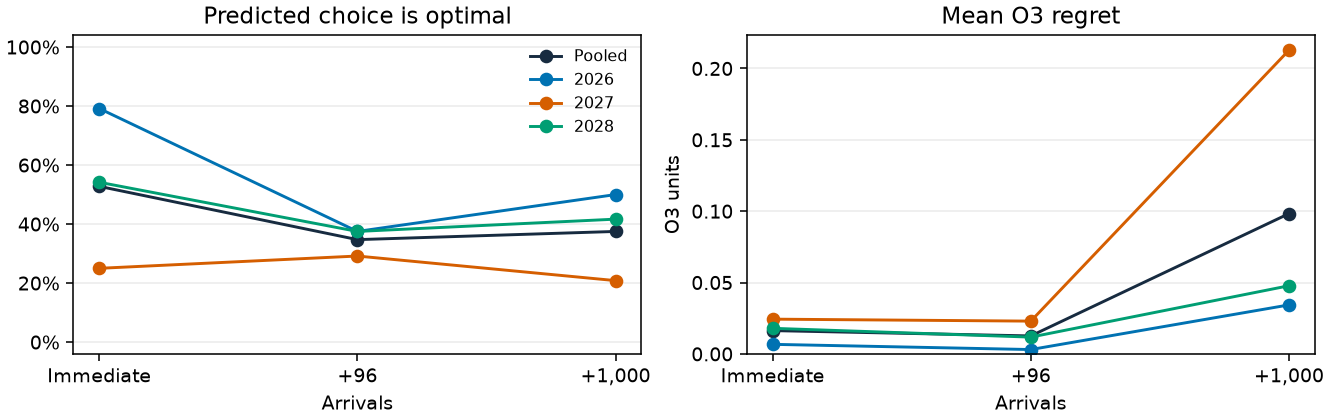

## Regret by initial-action selector

Each horizon pools 72 paired checkpoints. Regret is the measured O3 score of the selected branch minus the lowest measured O3 score at that checkpoint and horizon. Lower is better. Each selector controls the initial action. Uniform random averages the three branch regrets exactly. The oracle picks the measured winner in hindsight. Lasso O3 makes its original one-step choice, which is evaluated at all horizons.

### Mean regret in O3 units

| Initial-action selector | Immediate | +96 arrivals | +1,000 arrivals |
| --- | --- | --- | --- |
 | Lasso O3 | 0.01632 | 0.01258 | 0.09829 | 
 | Always ¼× | 0.02533 | 0.00717 | 0.07065 | 
 | Always 1× | 0.00807 | 0.01526 | 0.07782 | 
 | Always Skip | 0.03112 | 0.00989 | 0.07949 | 
 | Uniform random | 0.02151 | 0.01077 | 0.07599 | 
 | Oracle | 0.00000 | 0.00000 | 0.00000 | 

### Paired differences in mean regret

| Horizon | Reference selector | Lasso O3 minus reference | 95% paired interval |
| --- | --- | --- | --- |
 | 0 | Always ¼× | -0.00902 | [-0.01512, -0.00263] | 
 | 0 | Always 1× | +0.00825 | [-0.00535, +0.01984] | 
 | 0 | Always Skip | -0.01480 | [-0.02230, -0.00706] | 
 | 0 | Uniform random | -0.00519 | [-0.01137, +0.00005] | 
 | 96 | Always ¼× | +0.00541 | [+0.00137, +0.01034] | 
 | 96 | Always 1× | -0.00268 | [-0.00839, +0.00333] | 
 | 96 | Always Skip | +0.00270 | [-0.00195, +0.00968] | 
 | 96 | Uniform random | +0.00181 | [-0.00024, +0.00427] | 
 | 1000 | Always ¼× | +0.02764 | [-0.02377, +0.09008] | 
 | 1000 | Always 1× | +0.02047 | [-0.00832, +0.05400] | 
 | 1000 | Always Skip | +0.01880 | [-0.00313, +0.04973] | 
 | 1000 | Uniform random | +0.02230 | [-0.00059, +0.04778] | 

Positive differences favor the reference. Each unadjusted percentile interval resamples the 24 shared arrival positions with all three seeds kept together. The intervals are conditional on the sampled trajectories and fixed ¼× continuation.

### Measured action gaps

| Horizon | Measured gap | Median | 90th percentile | ≤0.001 | ≤0.01 |
| --- | --- | --- | --- | --- | --- |
 | 0 | Best to runner-up | 0.01752 | 0.04283 | 2.8% | 30.6% | 
 | 0 | Best to worst | 0.02659 | 0.07770 | 0.0% | 18.1% | 
 | 96 | Best to runner-up | 0.00151 | 0.02178 | 37.5% | 83.3% | 
 | 96 | Best to worst | 0.00458 | 0.04558 | 9.7% | 68.1% | 
 | 1000 | Best to runner-up | 0.01242 | 0.15830 | 18.1% | 47.2% | 
 | 1000 | Best to worst | 0.03791 | 0.41514 | 6.9% | 34.7% | 

In the figure, each point is a checkpoint and each diamond is the median pairwise difference. A negative difference favors the first action shown in the row. The lower panels show the cumulative gap from the best to the second-best and worst actions. The horizontal axes are linear near zero and logarithmic farther away. The dotted line marks 0.01 O3 units. The two cutoffs describe the observed scale of the gaps.


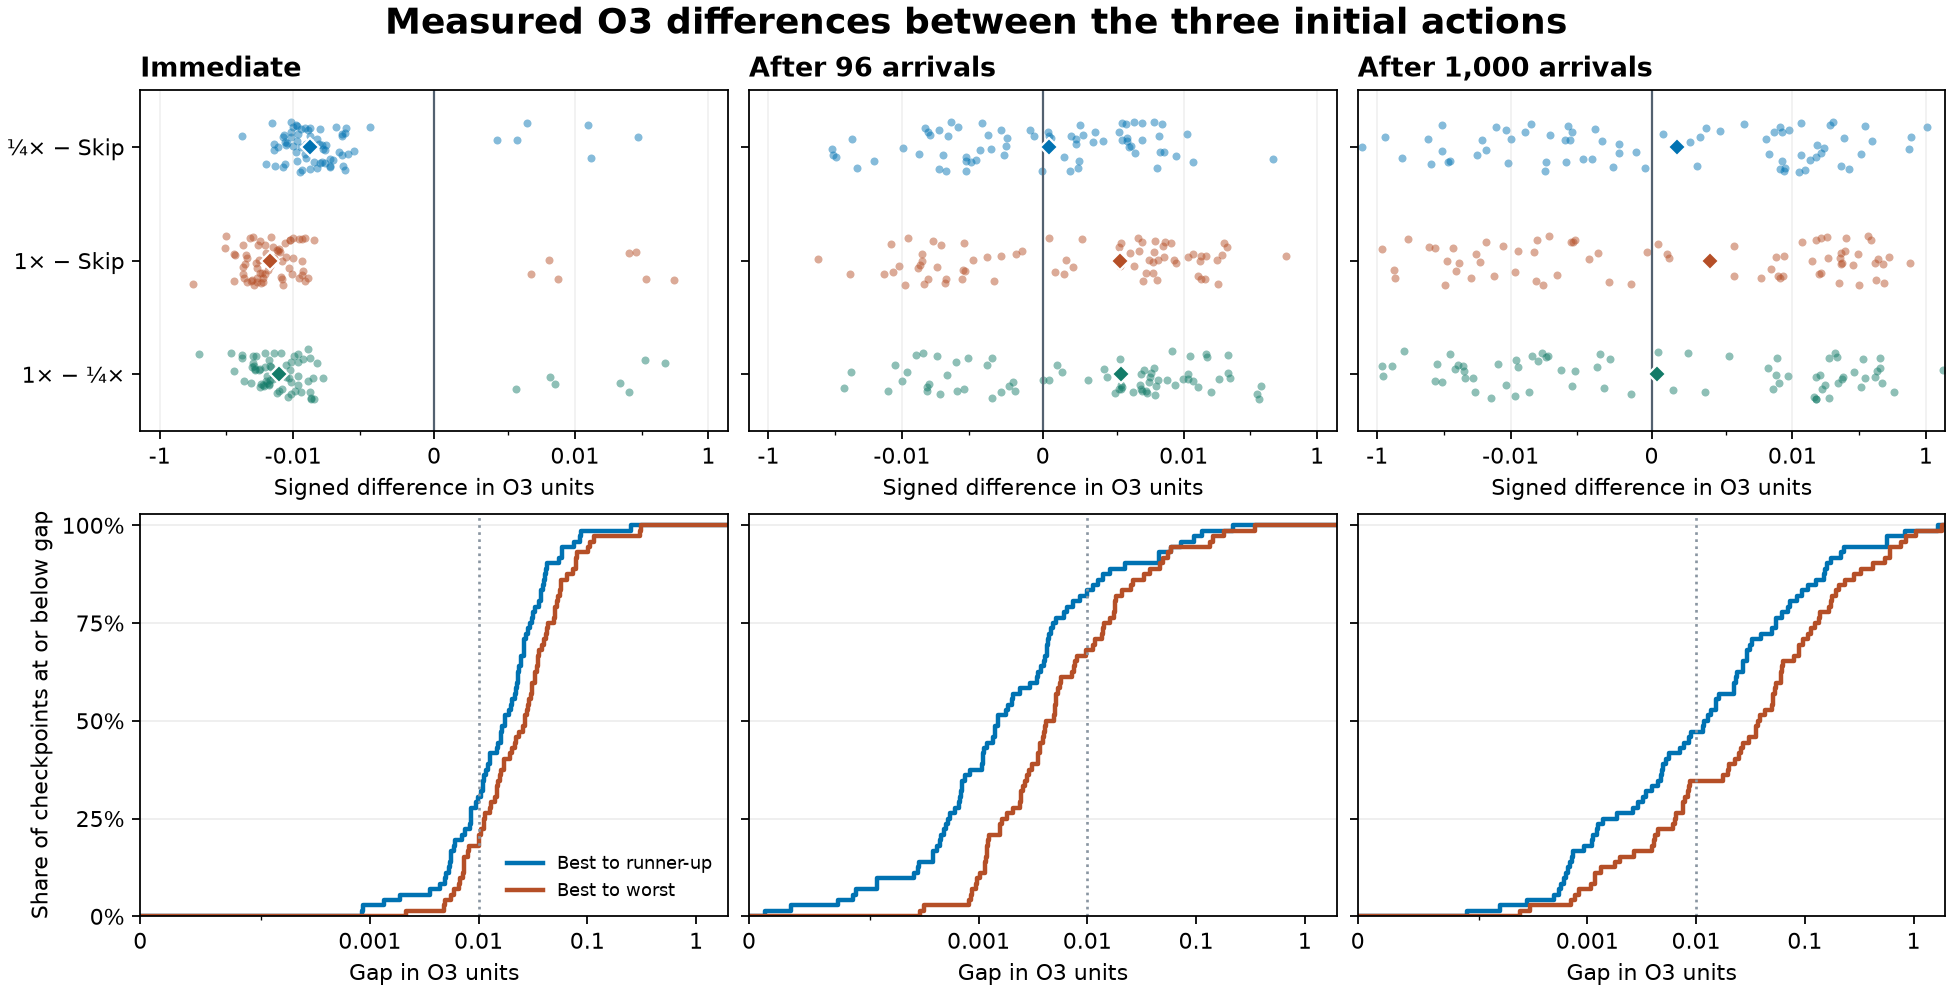

### Median and upper-tail regret

| Horizon | Initial-action selector | Median regret | 90th percentile regret |
| --- | --- | --- | --- |
 | 0 | Lasso O3 | 0.00000 | 0.04056 | 
 | 0 | Always ¼× | 0.01752 | 0.04283 | 
 | 0 | Always 1× | 0.00000 | 0.00000 | 
 | 0 | Always Skip | 0.02191 | 0.05661 | 
 | 0 | Uniform random | 0.01011 | 0.05108 | 
 | 0 | Oracle | 0.00000 | 0.00000 | 
 | 96 | Lasso O3 | 0.00116 | 0.01801 | 
 | 96 | Always ¼× | 0.00114 | 0.00974 | 
 | 96 | Always 1× | 0.00194 | 0.03247 | 
 | 96 | Always Skip | 0.00020 | 0.01792 | 
 | 96 | Uniform random | 0.00108 | 0.01817 | 
 | 96 | Oracle | 0.00000 | 0.00000 | 
 | 1000 | Lasso O3 | 0.00429 | 0.20603 | 
 | 1000 | Always ¼× | 0.00465 | 0.12619 | 
 | 1000 | Always 1× | 0.00622 | 0.20603 | 
 | 1000 | Always Skip | 0.00133 | 0.15280 | 
 | 1000 | Uniform random | 0.00394 | 0.17186 | 
 | 1000 | Oracle | 0.00000 | 0.00000 | 

Uniform random percentiles use the full equal-weight distribution of the three branches at every checkpoint.

### Mean regret by seed

| Seed | Horizon | Lasso O3 | Always ¼× | Always 1× | Always Skip | Uniform random |
| --- | --- | --- | --- | --- | --- | --- |
 | 2026 | 0 | 0.00669 | 0.01610 | 0.00509 | 0.02132 | 0.01417 | 
 | 2026 | 96 | 0.00304 | 0.00230 | 0.00596 | 0.00356 | 0.00394 | 
 | 2026 | 1000 | 0.03432 | 0.03200 | 0.05006 | 0.01651 | 0.03285 | 
 | 2027 | 0 | 0.02434 | 0.03141 | 0.01574 | 0.03600 | 0.02772 | 
 | 2027 | 96 | 0.02296 | 0.00726 | 0.01961 | 0.02225 | 0.01637 | 
 | 2027 | 1000 | 0.21280 | 0.11793 | 0.13057 | 0.20756 | 0.15202 | 
 | 2028 | 0 | 0.01792 | 0.02849 | 0.00337 | 0.03603 | 0.02263 | 
 | 2028 | 96 | 0.01175 | 0.01195 | 0.02022 | 0.00384 | 0.01201 | 
 | 2028 | 1000 | 0.04775 | 0.06201 | 0.05283 | 0.01442 | 0.04309 | 
